# Spectroscopic richness: weighting comparison
Three panels: unweighted, geometry + completeness, then LF. The same positive cluster sample is used in every panel. No trend fitting or MCMC. Individual points have no measurement-error bars; binned geometric means have SEM in log space, transformed to linear units.
Catalog generation (`make_catalogs/projection_match_catalogs.py`) stores all richness stages in `catalogs/bgs_clus_RM_gal_matched_with_weights.fits`. This notebook only reads those saved columns. There is no preparation or continuum-fitting step in the plotting workflow.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
REPO_ROOT = Path('/global/homes/z/zzhang13/DESI/Projection')
if not REPO_ROOT.exists():
    REPO_ROOT = Path.cwd().resolve()
    while REPO_ROOT != REPO_ROOT.parent and not (REPO_ROOT / 'richness_relation').is_dir():
        REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'richness_relation').is_dir():
    raise FileNotFoundError('Set REPO_ROOT to the repository directory')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from richness_relation.richness_catalog import load_stages
from richness_relation.plot_richness_weighting_comparison import plot_relation
from richness_relation.weighting_plot_utils import save
DATA_PATH = REPO_ROOT / 'catalogs/bgs_clus_RM_gal_matched_with_weights.fits'
OUTPUT_DIR = REPO_ROOT / 'plots/richness_weighting'
RM_BINS = np.geomspace(20, 100, 9)
MIN_COUNT = 20
XLIM = (20, 100)
YLIM = None  # Set e.g. (5, 300); None includes all positive plotted values.
clusters, audit = load_stages(DATA_PATH)
display(audit)
display(clusters[:5])

{'input_path': '/global/u1/z/zzhang13/DESI/Projection/catalogs/bgs_clus_RM_gal_matched_with_weights.fits',
 'matched_rows': 436628,
 'clusters': 15129,
 'catalog_metadata': {'EXTNAME': 'LSS',
  'RICHVER': 1,
  'CONTDEG': 6,
  'CONTWIN': 5},
 'note': 'Only reading saved columns; no richness or continuum calculation.'}

ID,Z_SPEC_central,LAMBDA,LF_WEIGHT,lambda_spec_unweighted,lambda_spec_geo_comp,lambda_spec_geo_comp_lf
int32,float64,float64,float64,float64,float64,float64
1,0.09080672264099121,169.8378448486328,1.0,nan,nan,nan
1000,0.25446566939353943,86.40838623046875,5.542084305552134,20.65808776239795,50.6695066763959,280.81467772132277
10003,0.33746179938316345,40.33836364746094,16.366809617083675,5.583266962810257,3.607393609486828,59.04152442035521
10005,0.41367948055267334,53.16780090332031,52.530478172872726,nan,nan,nan
10006,0.21071095764636993,27.356382369995117,3.3288201622692855,21.216414458678976,27.68546534418274,92.15993523952308


Common positive sample: 7345/15129 clusters; nonpositive values are excluded, never floored.


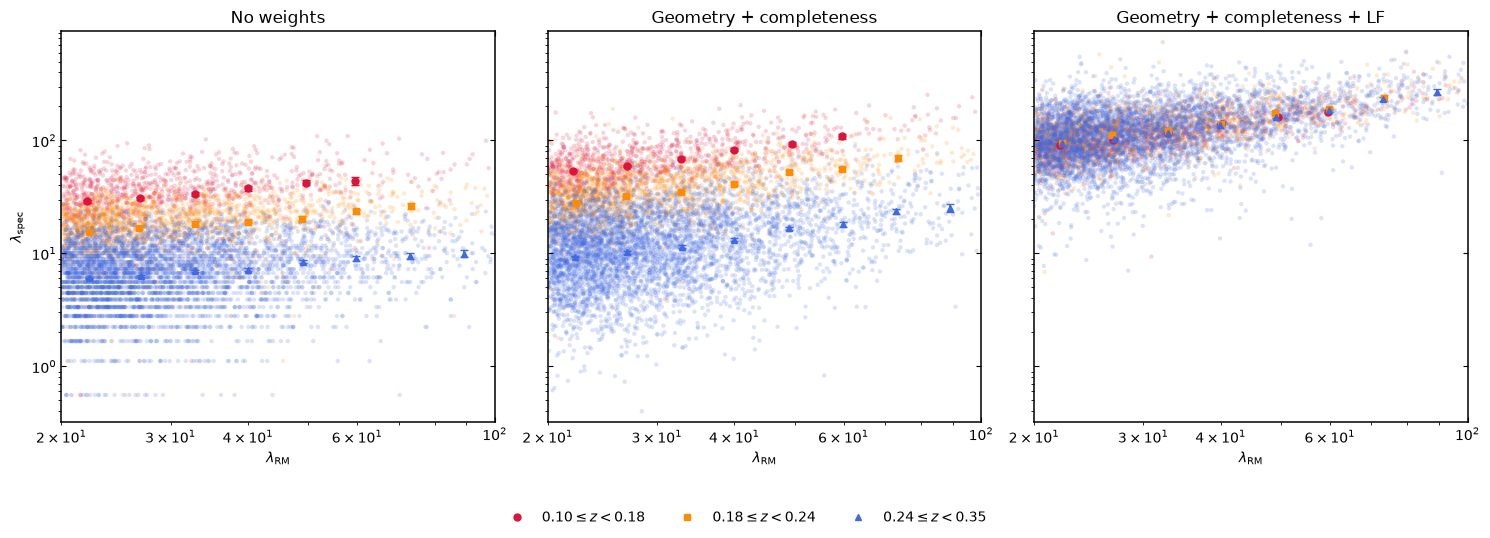

In [2]:
fig = plot_relation(clusters, rm_bins=RM_BINS, min_count=MIN_COUNT, xlim=XLIM, ylim=YLIM)
save(fig, OUTPUT_DIR, 'richness_weighting_comparison')
plt.show()
plt.close(fig)

## Additional plot for lambda_spec vs. lambda RM relation. 

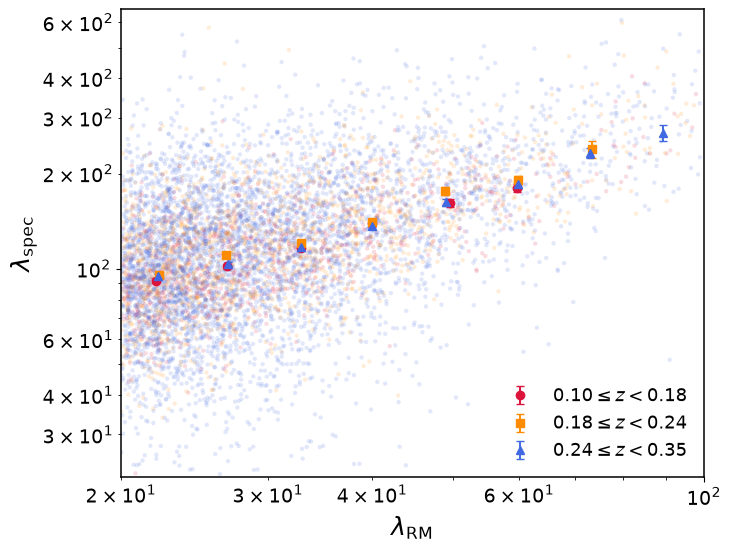

In [12]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path("/global/homes/z/zzhang13/DESI/Projection")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from richness_relation.richness_catalog import load_stages

# Reads saved richnesses and returns one row per cluster.
clusters, _ = load_stages(
    REPO_ROOT / "catalogs/bgs_clus_RM_gal_matched_with_weights.fits"
)

rm = np.asarray(clusters["LAMBDA"], dtype=float)
spec = np.asarray(clusters["lambda_spec_geo_comp_lf"], dtype=float)
z = np.asarray(clusters["Z_SPEC_central"], dtype=float)

Z_BINS = [(0.10, 0.18), (0.18, 0.24), (0.24, 0.35)]
RM_BINS = np.geomspace(20, 100, 9)  # Edit these edges as desired.
MIN_COUNT = 20
COLORS = ["crimson", "darkorange", "royalblue"]
MARKERS = ["o", "s", "^"]

valid = (
    np.isfinite(rm) & np.isfinite(spec) & np.isfinite(z)
    & (rm >= 20) & (rm <= 100) & (spec > 0)
)
fig, ax = plt.subplots(figsize=(7.2, 5.4), layout="constrained")

for (zlo, zhi), color, marker in zip(Z_BINS, COLORS, MARKERS):
    selected = valid & (z >= zlo) & (z < zhi)
    ax.scatter(
        rm[selected], spec[selected],
        s=10, alpha=0.15, color=color, edgecolors="none",
        rasterized=True,
    )

    x, y, lower, upper = [], [], [], []
    for ibin, (lo, hi) in enumerate(zip(RM_BINS[:-1], RM_BINS[1:])):
        right = rm <= hi if ibin == len(RM_BINS) - 2 else rm < hi
        use = selected & (rm >= lo) & right
        n = np.count_nonzero(use)
        if n < MIN_COUNT:
            continue

        log_spec = np.log10(spec[use])
        mean_log = np.mean(log_spec)
        sem_log = np.std(log_spec, ddof=1) / np.sqrt(n)
        mean_spec = 10**mean_log

        x.append(10**np.mean(np.log10(rm[use])))
        y.append(mean_spec)
        lower.append(mean_spec - 10**(mean_log - sem_log))
        upper.append(10**(mean_log + sem_log) - mean_spec)

    ax.errorbar(
        x, y, yerr=np.array([lower, upper]),
        fmt=marker, linestyle="none", color=color,
        markersize=6, capsize=3, elinewidth=1.4, zorder=5,
        label=rf"${zlo:.2f}\leq z<{zhi:.2f}$",
    )

ax.set(
    xscale="log", yscale="log", xlim=(20, 100),ylim= (22,660),
)

ax.set_xlabel(r"$\lambda_{\rm RM}$", fontsize=18)
ax.set_ylabel(r"$\lambda_{\rm spec}$", fontsize=18)

ax.grid(False)
ax.tick_params(axis="both", which="both", labelsize=14)
ax.legend(loc="best", frameon=False, fontsize=13)
for spine in ax.spines.values():
    spine.set_linewidth(1.1)

OUTPUT_DIR = REPO_ROOT / "plots" / "richness_weighting"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


fig.savefig(
        OUTPUT_DIR / f"lambda_spec_vs_lambda_RM_full_weights.jpg",
        dpi=300,
        bbox_inches="tight",
    )


plt.show()